# Linear Regression Project Exercise 

Now that we have learned about feature engineering, cross validation, and grid search, let's test all your new skills with a project exercise in Machine Learning. This exercise will have a more guided approach, later on the ML projects will begin to be more open-ended. We'll start off with using the final version of the Ames Housing dataset we worked on through the feature engineering section of the course. Your goal will be to create a Linear Regression Model, train it on the data with the optimal parameters using a grid search, and then evaluate the model's capabilities on a test set.

---
---
---
## Complete the tasks in bold

**TASK: Run the cells under the Imports and Data section to make sure you have imported the correct general libraries as well as the correct datasets. Later on you may need to run further imports from scikit-learn.**

### Imports

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Data

In [25]:
df = pd.read_csv("./datasets/AMES_Final_DF.csv")

In [26]:
df.head()

,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,141.0,31770,6,5,1960,1960,112.0,639.0,0.0,441.0,...,0,0,0,0,1,0,0,0,1,0
1,80.0,11622,5,6,1961,1961,0.0,468.0,144.0,270.0,...,0,0,0,0,1,0,0,0,1,0
2,81.0,14267,6,6,1958,1958,108.0,923.0,0.0,406.0,...,0,0,0,0,1,0,0,0,1,0
3,93.0,11160,7,5,1968,1968,0.0,1065.0,0.0,1045.0,...,0,0,0,0,1,0,0,0,1,0
4,74.0,13830,5,5,1997,1998,0.0,791.0,0.0,137.0,...,0,0,0,0,1,0,0,0,1,0


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2925 entries, 0 to 2924
Columns: 274 entries, Lot Frontage to Sale Condition_Partial
dtypes: float64(11), int64(263)
memory usage: 6.1 MB


**TASK: Perform some basic EDA(Exploratory Data Analysis).**

In [28]:
df.describe()

,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
count,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,...,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000
mean,69.683099,10109.861538,6.091624,5.563761,1971.323761,1984.229060,100.318632,438.974359,49.790427,558.959316,...,0.002735,0.080684,0.002393,0.000342,0.866325,0.004103,0.007863,0.015726,0.824615,0.082735
std,21.344161,7785.509739,1.406386,1.112262,30.228826,20.857822,176.667803,439.426274,169.274143,439.729905,...,0.052235,0.272395,0.048870,0.018490,0.340361,0.063931,0.088341,0.124437,0.380361,0.275528
min,0.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,60.000000,7438.000000,5.000000,5.000000,1954.000000,1965.000000,0.000000,0.000000,0.000000,218.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,70.000000,9430.000000,6.000000,5.000000,1973.000000,1993.000000,0.000000,370.000000,0.000000,465.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,80.000000,11526.000000,7.000000,6.000000,2000.000000,2004.000000,162.000000,734.000000,0.000000,801.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,2288.000000,1526.000000,2336.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


**TASK: The label we are trying to predict is the SalePrice column. Separate out the data into X features and y labels**

In [29]:
#splitting
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

In [30]:
print(X.shape)
print(y.shape)

(2925, 273)
(2925,)


In [31]:
X

,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,141.000000,31770,6,5,1960,1960,112.0,639.0,0.0,441.0,...,0,0,0,0,1,0,0,0,1,0
1,80.000000,11622,5,6,1961,1961,0.0,468.0,144.0,270.0,...,0,0,0,0,1,0,0,0,1,0
2,81.000000,14267,6,6,1958,1958,108.0,923.0,0.0,406.0,...,0,0,0,0,1,0,0,0,1,0
3,93.000000,11160,7,5,1968,1968,0.0,1065.0,0.0,1045.0,...,0,0,0,0,1,0,0,0,1,0
4,74.000000,13830,5,5,1997,1998,0.0,791.0,0.0,137.0,...,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2920,37.000000,7937,6,6,1984,1984,0.0,819.0,0.0,184.0,...,0,0,0,0,1,0,0,0,1,0
2921,75.144444,8885,5,5,1983,1983,0.0,301.0,324.0,239.0,...,0,0,0,0,1,0,0,0,1,0
2922,62.000000,10441,5,5,1992,1992,0.0,337.0,0.0,575.0,...,0,0,0,0,1,0,0,0,1,0
2923,77.000000,10010,5,5,1974,1975,0.0,1071.0,123.0,195.0,...,0,0,0,0,1,0,0,0,1,0


**TASK: Use scikit-learn to split up X and y into a training set and test set. Since we will later be using a Grid Search strategy, set your test proportion to 10%. To get the same data split as the solutions notebook, you can specify random_state = 101**

In [32]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=101)

In [33]:
print(X_train.shape)
print(y_train.shape)

(2632, 273)
(2632,)


**TASK: The dataset features has a variety of scales and units. For optimal regression performance, scale the X features. Take carefuly note of what to use for .fit() vs what to use for .transform()**

In [34]:
from sklearn.preprocessing import StandardScaler

X_train_unscaled = X_train.copy() #for comparison after scalling

scaler = StandardScaler()
scaler.fit(X_train) # fit on train only so test stats don't leak in
scaled_X_train = scaler.transform(X_train)
scaled_X_test  = scaler.transform(X_test)

In [35]:
scaled_X_train.mean().round(2) # the scaler used the std and mean it learned to make the training data have a mean of 0

np.float64(0.0)

In [36]:
scaled_X_train.mean(axis=0).round(2)

array([ 0.,  0.,  0.,  0., -0., -0.,  0., -0.,  0.,  0.,  0., -0.,  0.,
        0., -0.,  0.,  0., -0., -0., -0.,  0., -0., -0.,  0.,  0., -0.,
        0., -0., -0.,  0.,  0., -0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
       -0.,  0., -0., -0., -0.,  0.,  0., -0.,  0., -0., -0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0., -0., -0.,  0.,  0.,  0.,  0.,  0.,
       -0., -0., -0.,  0.,  0.,  0.,  0., -0., -0., -0.,  0.,  0.,  0.,
        0., -0.,  0., -0.,  0., -0., -0., -0., -0., -0.,  0.,  0.,  0.,
       -0., -0.,  0., -0.,  0., -0., -0.,  0.,  0.,  0., -0.,  0., -0.,
       -0., -0.,  0., -0., -0.,  0., -0., -0.,  0., -0., -0., -0.,  0.,
       -0., -0.,  0., -0., -0.,  0., -0.,  0.,  0., -0.,  0., -0., -0.,
        0.,  0., -0.,  0., -0.,  0., -0., -0.,  0., -0.,  0.,  0., -0.,
        0.,  0.,  0., -0.,  0.,  0., -0., -0.,  0., -0.,  0.,  0., -0.,
       -0., -0.,  0.,  0.,  0., -0., -0.,  0.,  0.,  0., -0.,  0., -0.,
        0.,  0.,  0.,  0., -0., -0.,  0., -0., -0., -0., -0.,  0

In [37]:
scaled_X_test.mean().round(2) # slightly off, has -0.0 since the scaler didn't learn form it.

np.float64(-0.0)

In [38]:
scaled_X_test.mean(axis=0).round(2) # plot each column and you will see the mean clearly.

array([ 0.09,  0.08,  0.08, -0.02,  0.06,  0.08, -0.02,  0.04, -0.03,
        0.06,  0.09,  0.03,  0.05, -0.07,  0.06, -0.  , -0.04,  0.08,
        0.03,  0.14, -0.02,  0.11, -0.01,  0.07,  0.06,  0.05, -0.  ,
        0.01, -0.02, -0.08, -0.04, -0.06, -0.01, -0.15,  0.15, -0.02,
        0.  , -0.03, -0.  , -0.08,  0.  ,  0.03, -0.04, -0.05,  0.13,
       -0.03,  0.03, -0.05, -0.02,  0.  , -0.02,  0.  , -0.03, -0.07,
        0.08, -0.06,  0.01, -0.06,  0.03,  0.01, -0.06, -0.03,  0.07,
       -0.02, -0.03, -0.05, -0.12, -0.02,  0.02,  0.01, -0.03, -0.06,
        0.08, -0.02,  0.05,  0.07, -0.01,  0.04,  0.01, -0.06, -0.03,
       -0.09, -0.02, -0.12, -0.05, -0.1 , -0.01, -0.02,  0.05,  0.07,
       -0.03, -0.02,  0.09,  0.12, -0.02, -0.06,  0.02, -0.02, -0.1 ,
        0.07,  0.15, -0.03, -0.03, -0.03,  0.03,  0.01, -0.02,  0.03,
       -0.04,  0.1 , -0.02, -0.02, -0.03, -0.01,  0.  , -0.02,  0.09,
       -0.04,  0.01,  0.01, -0.02,  0.11, -0.07, -0.07,  0.07,  0.04,
       -0.07, -0.06,

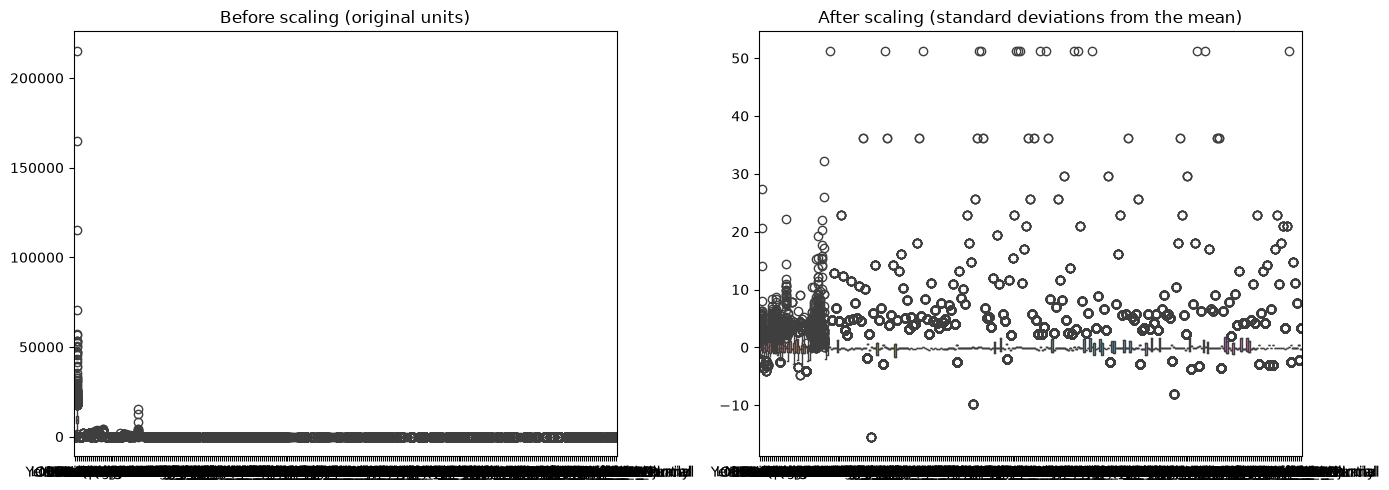

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=X_train_unscaled, ax=axes[0])
axes[0].set_title('Before scaling (original units)')

sns.boxplot(data=pd.DataFrame(scaled_X_train, columns=X.columns), ax=axes[1])
axes[1].set_title('After scaling (standard deviations from the mean)')

plt.tight_layout()
plt.show()

##### -> This plot is not very undestandble but each dot is a boxplot, and I can see the line moved to the mean "0" which means the scalling worked, we just have a lot of outliers and need ElasticNet to find the features we actually need.

**TASK: We will use an Elastic Net model. Create an instance of default ElasticNet model with scikit-learn**

In [40]:
from sklearn.linear_model import ElasticNet

In [41]:
base_model = ElasticNet(max_iter=1000000) #max iterations increases the number of tries since we have too many features.

**TASK:  The Elastic Net model has two main parameters, alpha and the L1 ratio. Create a dictionary parameter grid of values for the ElasticNet. Feel free to play around with these values, keep in mind, you may not match up exactly with the solution choices**

In [42]:
# less values to see if the code works first then use more.
param_grid = {
    'alpha': [0.1,1,5,10,50,100], 
    'l1_ratio': [.1, .5, .7, .9, .95, .99, 1] # .1 is Ridge and 1 is lasso 
}

**TASK: Using scikit-learn create a GridSearchCV object and run a grid search for the best parameters for your model based on your scaled training data.**

In [43]:
from sklearn.model_selection import GridSearchCV

In [44]:
# verbose number a personal preference
grid_model = GridSearchCV(estimator=base_model, # The base model to optimize (ElasticNet regression in this case)
                          param_grid=param_grid,
                          scoring='neg_mean_squared_error', #Negative MSE because GridSearch maximizes scores (lower MSE is better)
                          cv=5, # Each parameter combination is tested 5 times with different train/validation splits
                          verbose=1, # how much information GridSearchCV prints to the console during execution
                          n_jobs=-1 #use all CPU cores to run faster
                          ) 

In [45]:
grid_model.fit(scaled_X_train,y_train)

Fitting 5 folds for each of 42 candidates, totalling 210 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",ElasticNet(max_iter=1000000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.1, 1, ...], 'l1_ratio': [0.1, 0.5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see

**TASK: Display the best combination of parameters for your model**

In [46]:
grid_model.best_params_

{'alpha': 100, 'l1_ratio': 1}

**TASK: Evaluate your model's performance on the unseen 10% scaled test set. In the solutions notebook we achieved an MAE of $\$$14149 and a RMSE of $\$$20532**

In [47]:
#using the best model for predictions before evaluating the model
y_pred = grid_model.predict(scaled_X_test)
pd.DataFrame(y_pred).head()

,0
0,115030.010883
1,330700.153727
2,201207.127314
3,196378.724000
4,102219.743191


In [48]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

In [49]:
mean_absolute_error(y_test,y_pred)

14195.354900562175

In [50]:
root_mean_squared_error(y_test,y_pred)

20558.508566893182

### Extra visual: which features did ElasticNet keep?

Kept 207 of 273 features, dropped 66 (coefficient exactly 0)


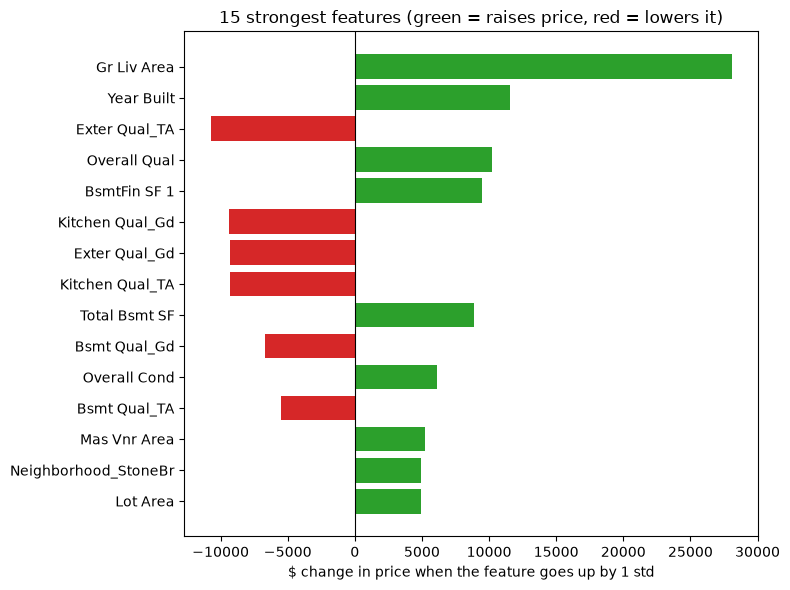

In [51]:
# the winning model that GridSearch retrained on all of scaled_X_train
best = grid_model.best_estimator_
coefs = pd.Series(best.coef_, index=X.columns)  # one number per feature

print(f"Kept {(coefs != 0).sum()} of {len(coefs)} features, dropped {(coefs == 0).sum()} (coefficient exactly 0)")

# the 15 features with the biggest effect, positive or negative
top = coefs[coefs.abs().sort_values(ascending=False).index[:15]]
colors = ['tab:green' if v > 0 else 'tab:red' for v in top]

plt.figure(figsize=(8, 6))
plt.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
plt.axvline(0, color='black', lw=0.8)
plt.title('15 strongest features (green = raises price, red = lowers it)')
plt.xlabel('$ change in price when the feature goes up by 1 std')
plt.tight_layout()
plt.show()

### Extra visual: predicted vs real price

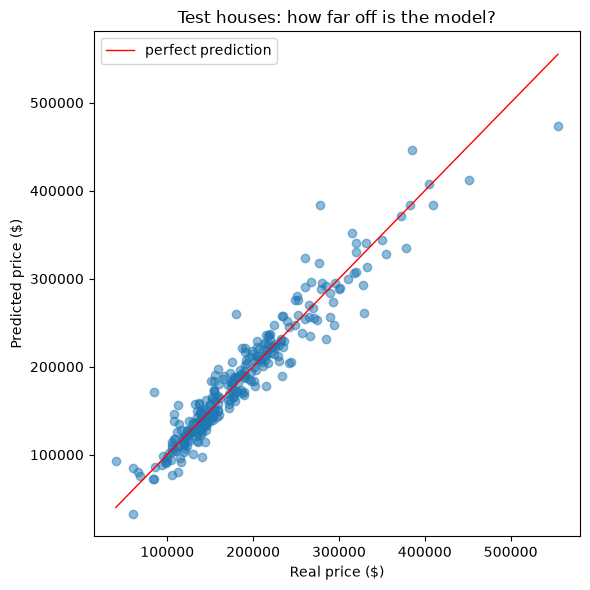

In [52]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color='red', lw=1, label='perfect prediction')  # dots on this line = exact guess
plt.xlabel('Real price ($)')
plt.ylabel('Predicted price ($)')
plt.title('Test houses: how far off is the model?')
plt.legend()
plt.tight_layout()
plt.show()

## Great work!

----